In [1]:
import json
import hashlib
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, RandomBrightness,
    RandomFlip, RandomRotation, RandomZoom
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

SEED = 42
IMG_SIZE = 150
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 1e-3

DATA_DIR = Path("dataset")
RESULT_DIR = Path("results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

print("Library berhasil di-import!")
print("Lokasi dataset:", DATA_DIR)

Library berhasil di-import!
Lokasi dataset: dataset


In [2]:
print("========== DATA CLEANING ==========")

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATA_DIR}")

class_dirs = sorted([f for f in DATA_DIR.iterdir() if f.is_dir()])
if len(class_dirs) < 2:
    raise ValueError("Folder kategori awan tidak ditemukan!")

classes = [f.name for f in class_dirs]
print("Kategori awan:", classes)

data = []
seen_hash = set()
corrupt_count = 0
duplicate_count = 0

for class_dir in class_dirs:
    label = class_dir.name
    for path in class_dir.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in EXTENSIONS:
            continue
        try:
            with Image.open(path) as img:
                img.verify()

            file_hash = hashlib.md5(path.read_bytes()).hexdigest()
            if file_hash in seen_hash:
                duplicate_count += 1
                continue
            seen_hash.add(file_hash)

            data.append({"filepath": str(path), "label": label})
        except Exception:
            corrupt_count += 1

df = pd.DataFrame(data)
if df.empty:
    raise ValueError("Tidak ada gambar valid!")

class_counts = df["label"].value_counts().sort_index()

print("\nHASIL DATA CLEANING")
print("Gambar valid    :", len(df))
print("Gambar rusak    :", corrupt_count)
print("Gambar duplikat :", duplicate_count)
print("\nJumlah gambar setiap kelas:")
print(class_counts)

df.to_csv(RESULT_DIR / "cleaned_dataset.csv", index=False)

========== DATA CLEANING ==========
Kategori awan: ['A-Clear Sky', 'B-Patterned Clouds', 'C-Thin White Clouds', 'D-Thick White Clouds', 'E-Thick Dark Clouds', 'F-Veil Clouds']

HASIL DATA CLEANING
Gambar valid    : 2064
Gambar rusak    : 0
Gambar duplikat : 36

Jumlah gambar setiap kelas:
label
A-Clear Sky             349
B-Patterned Clouds      346
C-Thin White Clouds     331
D-Thick White Clouds    349
E-Thick Dark Clouds     347
F-Veil Clouds           342
Name: count, dtype: int64


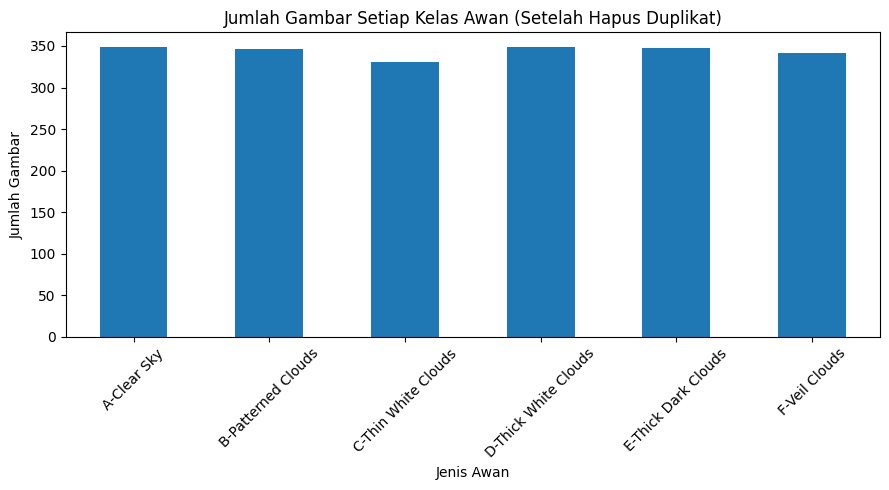

Pemetaan label: {'A-Clear Sky': 0, 'B-Patterned Clouds': 1, 'C-Thin White Clouds': 2, 'D-Thick White Clouds': 3, 'E-Thick Dark Clouds': 4, 'F-Veil Clouds': 5}
Training  : 1651
Validation: 206
Testing   : 207


In [3]:
plt.figure(figsize=(9, 5))
class_counts.plot(kind="bar")
plt.title("Jumlah Gambar Setiap Kelas Awan (Setelah Hapus Duplikat)")
plt.xlabel("Jenis Awan")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(RESULT_DIR / "dataset_distribution.png")
plt.show()

label_map = {name: i for i, name in enumerate(classes)}
df["encoded_label"] = df["label"].map(label_map)
print("Pemetaan label:", label_map)

train_df, temp_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["encoded_label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["encoded_label"]
)

print("Training  :", len(train_df))
print("Validation:", len(val_df))
print("Testing   :", len(test_df))

In [4]:
print("========== PREPROCESSING ==========")

def baca_gambar(filepath):
    gambar = Image.open(filepath)
    gambar = gambar.convert("RGB")
    gambar = gambar.resize((IMG_SIZE, IMG_SIZE))
    gambar = np.array(gambar)
    gambar = gambar / 255.0
    return gambar

def siapkan_data(dataframe):
    daftar_gambar = []
    daftar_label = []

    for i in range(len(dataframe)):
        baris = dataframe.iloc[i]
        daftar_gambar.append(baca_gambar(baris["filepath"]))
        daftar_label.append(baris["encoded_label"])

    X = np.array(daftar_gambar, dtype="float32")
    y = np.array(daftar_label)
    return X, y

X_train, y_train_int = siapkan_data(train_df)
X_val, y_val_int = siapkan_data(val_df)
X_test, y_test_int = siapkan_data(test_df)

num_classes = len(classes)
y_train = to_categorical(y_train_int, num_classes)
y_val = to_categorical(y_val_int, num_classes)
y_test = to_categorical(y_test_int, num_classes)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)
print("Nilai piksel min-max:", X_train.min(), "-", X_train.max())

========== PREPROCESSING ==========
X_train: (1651, 150, 150, 3)
X_val  : (206, 150, 150, 3)
X_test : (207, 150, 150, 3)
Nilai piksel min-max: 0.0 - 1.0


In [5]:
model = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    RandomFlip("horizontal"),
    RandomRotation(15 / 360),
    RandomZoom(0.1),
    RandomBrightness(0.1, value_range=(0, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(num_classes, activation="softmax"),
])

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 150, 150, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,566 (20.61 MB)

 Trainable params: 5,402,566 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1,
)

print("Epoch berjalan :", len(history.history["loss"]))
print("Learning rate  :", LEARNING_RATE)
print("Batch size     :", BATCH_SIZE)

Epoch 1/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 22s 372ms/step - accuracy: 0.4791 - loss: 1.3445 - val_accuracy: 0.7087 - val_loss: 0.9609
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 18s 339ms/step - accuracy: 0.6511 - loss: 0.9231 - val_accuracy: 0.7524 - val_loss: 0.7430
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 18s 338ms/step - accuracy: 0.7408 - loss: 0.7569 - val_accuracy: 0.7670 - val_loss: 0.7715
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 332ms/step - accuracy: 0.7620 - loss: 0.6821 - val_accuracy: 0.8010 - val_loss: 0.5991
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 334ms/step - accuracy: 0.7983 - loss: 0.5680 - val_accuracy: 0.8350 - val_loss: 0.5417
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 328ms/step - accuracy: 0.8395 - loss: 0.4780 - val_accuracy: 0.8641 - val_loss: 0.3913
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 18s 337ms/step - accuracy: 0.8328 - loss: 0.4692 - val_accuracy: 0.8835 - val_loss: 0.3495
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 18s 344ms/step - accuracy: 0.8595 - loss: 0.4079 - val_accu

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step
HASIL EVALUASI CNN (DATA TEST)
Accuracy : 0.9710
Precision: 0.9718
Recall   : 0.9709
F1-Score : 0.9710
                      precision    recall  f1-score   support

         A-Clear Sky       1.00      1.00      1.00        35
  B-Patterned Clouds       1.00      0.97      0.99        35
 C-Thin White Clouds       0.91      0.97      0.94        33
D-Thick White Clouds       0.92      0.94      0.93        35
 E-Thick Dark Clouds       1.00      1.00      1.00        35
       F-Veil Clouds       1.00      0.94      0.97        34

            accuracy                           0.97       207
           macro avg       0.97      0.97      0.97       207
        weighted avg       0.97      0.97      0.97       207



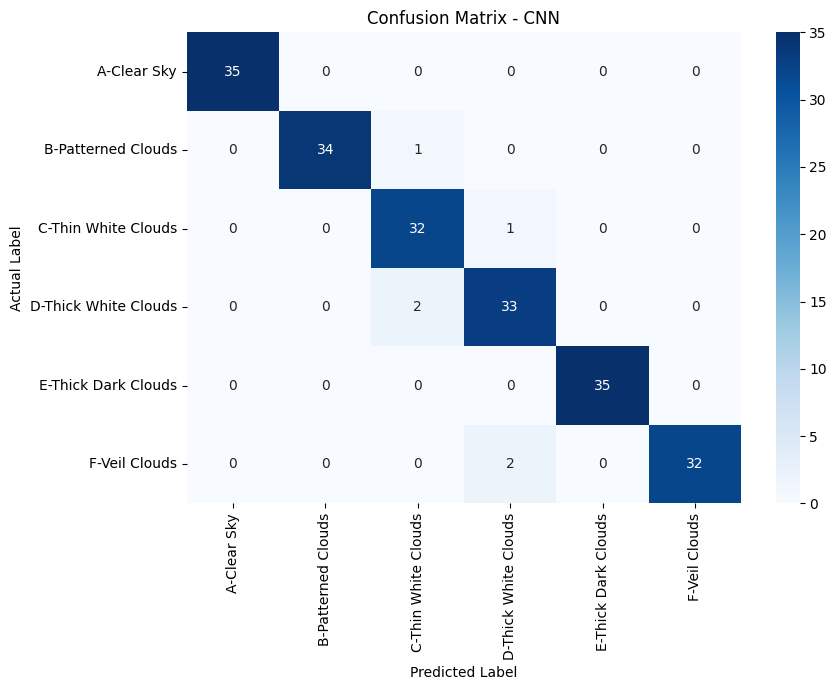

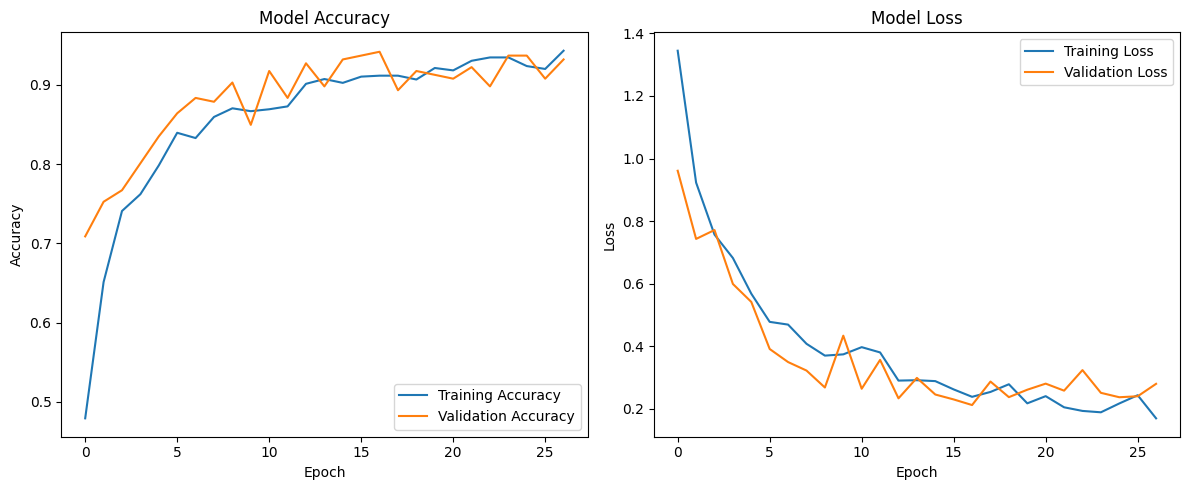

In [7]:
y_pred = np.argmax(model.predict(X_test), axis=1)

accuracy = accuracy_score(y_test_int, y_pred)
precision = precision_score(y_test_int, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test_int, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test_int, y_pred, average="macro", zero_division=0)

print("HASIL EVALUASI CNN (DATA TEST)")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

report = classification_report(
    y_test_int, y_pred,
    labels=list(range(num_classes)),
    target_names=classes,
    zero_division=0,
)
print(report)
with open(RESULT_DIR / "classification_report.txt", "w") as f:
    f.write(report)

cm = confusion_matrix(y_test_int, y_pred, labels=list(range(num_classes)))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix - CNN")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(RESULT_DIR / "confusion_matrix.png")
plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig(RESULT_DIR / "training_graph.png")
plt.show()

model.save(RESULT_DIR / "cnn_awan.keras")

with open(RESULT_DIR / "label_mapping.json", "w") as f:
    json.dump(label_map, f, indent=4)

metrics = {
    "accuracy": float(accuracy),
    "precision_macro": float(precision),
    "recall_macro": float(recall),
    "f1_macro": float(f1),
    "epochs_run": len(history.history["loss"]),
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
}
with open(RESULT_DIR / "evaluation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)